# Mini Challenge 2026: Hotel revenue forecasting

**Goal:** forecast the daily `Revenue` of one US city 1 to 7 days ahead, with the 2013-2020 data. The city is chosen in the EDA (2.1), not in advance.

Steps:
1. Data loading (all 8 cities)
2. Exploratory analysis and choice of the city
3. Transformations and stationarity
4. Cross-validation setup and baselines
5. Model building (ETS, ARIMA)
6. Results

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import boxcox
from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import MSTL
import statsmodels.api as sm
from statsforecast.models import AutoETS, AutoARIMA  # pip install statsforecast
from statsforecast.arima import arima_string

warnings.filterwarnings('ignore')  # KPSS warns when the p-value is outside its table
plt.rcParams['figure.figsize'] = (14, 4)

## 1. Data loading
One column of `Revenue` per city, 2013-2020, daily frequency (a missing day would appear as NaN).

In [2]:
df = pd.read_pickle('Data/hotels.pk')
rev = df.pivot(columns='Location', values='Revenue').loc['2013':'2020'].asfreq('D')
COVID = '2020-03-01'

print(rev.shape, '| missing values:', rev.isna().sum().sum())
rev.describe().T

(2861, 8) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
Location,,,,,,,,
Atlanta,2861.0,1.214674e+06,4.040645e+05,300130.994748,9.193944e+05,1.181489e+06,1.496782e+06,3.527372e+06
Boston,2861.0,8.151052e+05,3.765285e+05,114523.553351,5.037029e+05,7.861201e+05,1.087058e+06,2.035877e+06
Chicago,2861.0,1.275021e+06,5.327550e+05,191560.618017,8.693120e+05,1.235056e+06,1.649091e+06,3.194662e+06
Dallas,2861.0,9.534181e+05,3.138103e+05,246828.548026,7.192026e+05,9.331464e+05,1.171726e+06,2.042266e+06
LosAngeles,2861.0,1.047586e+06,3.072564e+05,164409.176800,8.223213e+05,1.029759e+06,1.284525e+06,1.839768e+06
NewYork,2861.0,3.152937e+06,1.208497e+06,588695.817812,2.275864e+06,3.191277e+06,3.961953e+06,7.940696e+06
Orlando,2861.0,1.860535e+06,6.914702e+05,88994.827420,1.484438e+06,1.885469e+06,2.270487e+06,4.346277e+06
Washington,2861.0,1.527573e+06,5.976716e+05,275723.044727,1.074773e+06,1.516478e+06,1.933002e+06,3.974323e+06


## 2. Exploratory analysis
### 2.1 Comparing the cities and choosing one
Pre-COVID period, each city divided by its mean so the levels are comparable.

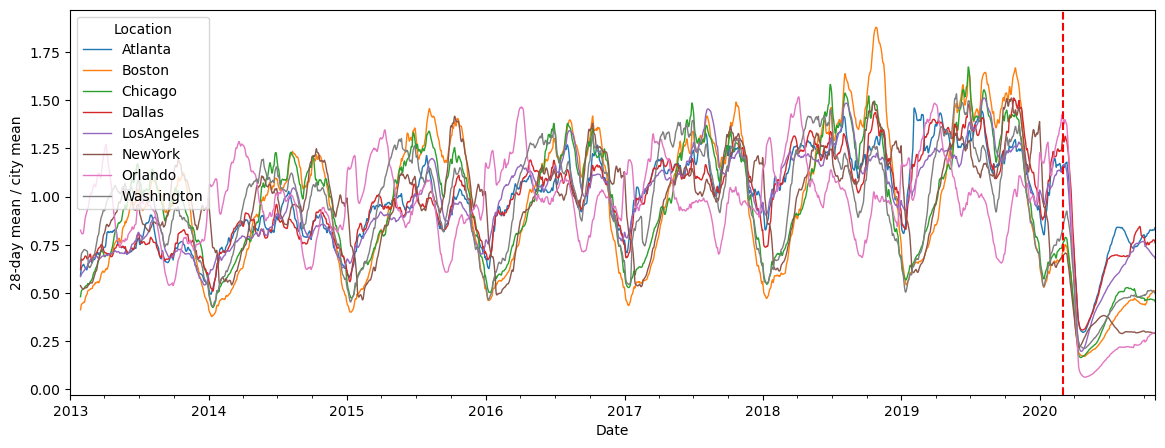

In [3]:
(rev / rev.loc[:'2019'].mean()).rolling(28).mean().plot(lw=1, figsize=(14, 5))
plt.axvline(COVID, c='r', ls='--')
plt.ylabel('28-day mean / city mean');

Forecastability indicators (2013-2019):
* **ACF lag 7 / 364:** strength of the weekly / yearly pattern (higher = better).
* **Variance ratio** $\operatorname{Var}(\Delta y_t) / \operatorname{Var}(y_t)$: size of the day-to-day changes (lower = better).
* **Spectral entropy:** low when a few periodicities dominate (lower = better).
* **MAPE of the weekly seasonal naive on 2019:** how well the simplest seasonal model works.

We choose the city with the lowest seasonal-naive MAPE, the indicator closest to our task.

In [4]:
pre = rev.loc[:'2019']


def spec_entropy(s):
    p = periodogram(s - s.mean())[1][1:]  # without the zero frequency
    p = p / p.sum()
    return -(p * np.log(p + 1e-12)).sum() / np.log(len(p))


def snaive_mape(s):
    err = abs(s - s.shift(7)) / s
    return err.loc['2019'].mean() * 100


rows = {}

for city in pre.columns:
    s = pre[city]
    rows[city] = {
        'ACF lag 7': s.autocorr(7),
        'ACF lag 364': s.autocorr(364),
        'Var ratio': s.diff().var() / s.var(),
        'Spec entropy': spec_entropy(s),
        'MAPE snaive7 2019 [%]': snaive_mape(s),
    }

stats = pd.DataFrame(rows).T.sort_values('MAPE snaive7 2019 [%]').round(3)

CITY = stats.index[0]
print('Selected city:', CITY)
stats

Selected city: LosAngeles


,ACF lag 7,ACF lag 364,Var ratio,Spec entropy,MAPE snaive7 2019 [%]
LosAngeles,0.826,0.920,0.352,0.450,12.119
Dallas,0.735,0.893,0.573,0.537,17.865
Orlando,0.559,0.807,0.380,0.567,19.292
NewYork,0.681,0.903,0.411,0.506,19.504
Atlanta,0.639,0.837,0.568,0.577,20.244
Boston,0.807,0.905,0.320,0.400,21.526
Washington,0.714,0.890,0.382,0.488,21.677
Chicago,0.698,0.901,0.475,0.457,22.337


**Observations:**
* All cities: growth until 2017, summer peak, collapse in March 2020.
* **Los Angeles** has the strongest weekly pattern (ACF lag 7 = 0.83) and the lowest seasonal-naive error (12.1%, Dallas second with 17.9%).
* Boston is slightly better on variance ratio and spectral entropy, thanks to its strong yearly cycle, but this does not help at 1-7 days (seasonal-naive error 21.5%).
* Note: the seasonal-naive check uses 2019, which is also our test year; a stricter choice would use only earlier years.

In [5]:
data = df[df['Location'] == CITY].drop(columns='Location').loc['2013':'2020'].asfreq('D')
y = data['Revenue']
y_pre = y.loc[:'2019-12-31']

### 2.2 Time plot

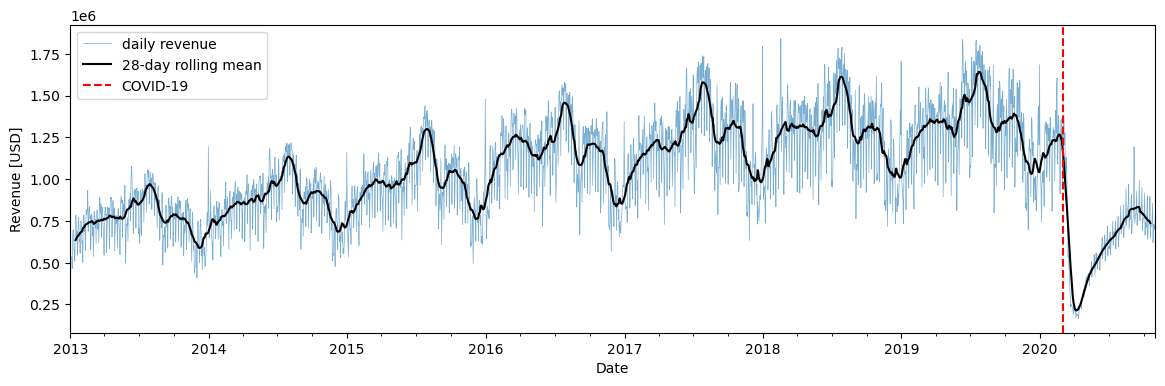

In [6]:
ax = y.plot(lw=0.5, alpha=0.6, label='daily revenue')
y.rolling(28, center=True).mean().plot(ax=ax, c='k', label='28-day rolling mean')
ax.axvline(COVID, c='r', ls='--', label='COVID-19')
ax.set_ylabel('Revenue [USD]')
ax.legend();

**Observations:**
* Growth until 2017, then roughly stable.
* Summer peak and end-of-year drop every year.
* Strong weekly cycle, wider when the level is higher: multiplicative seasonality.
* March 2020: -85% (about 200k USD), only partly recovered by October.

### 2.3 Calendar distributions
Pre-COVID only.

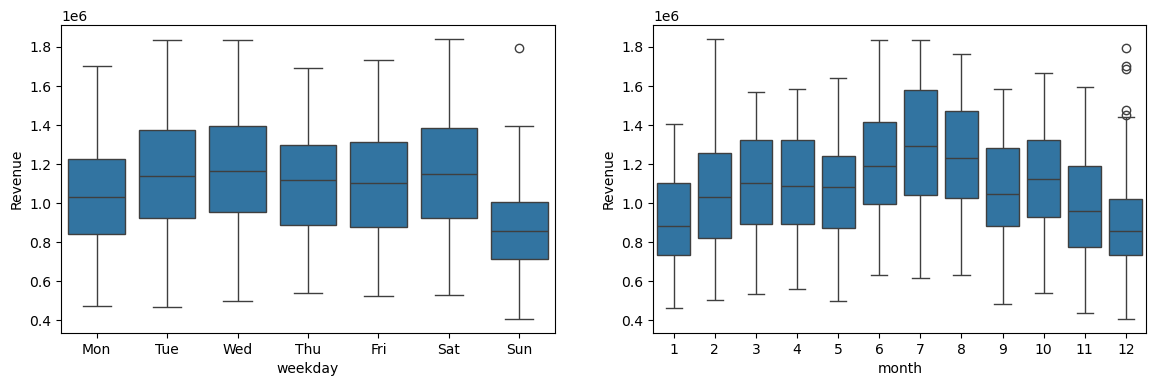

In [7]:
cal = pd.DataFrame({'Revenue': y_pre, 'weekday': y_pre.index.day_name().str[:3], 'month': y_pre.index.month})

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sb.boxplot(cal, x='weekday', y='Revenue', ax=ax[0], order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
sb.boxplot(cal, x='month', y='Revenue', ax=ax[1]);

**Observations:**
* Sunday is the weakest day, then Monday; Tuesday, Wednesday and Saturday are the strongest.
* High season June-August, low season January and December (the high December values are holidays).

### 2.4 Correlation with the other variables
`Demand` and `Occupancy` are known only up to today, so they could only be used lagged.

           Revenue  Demand  Occupancy
Revenue       1.00    0.96       0.76
Demand        0.96    1.00       0.86
Occupancy     0.76    0.86       1.00


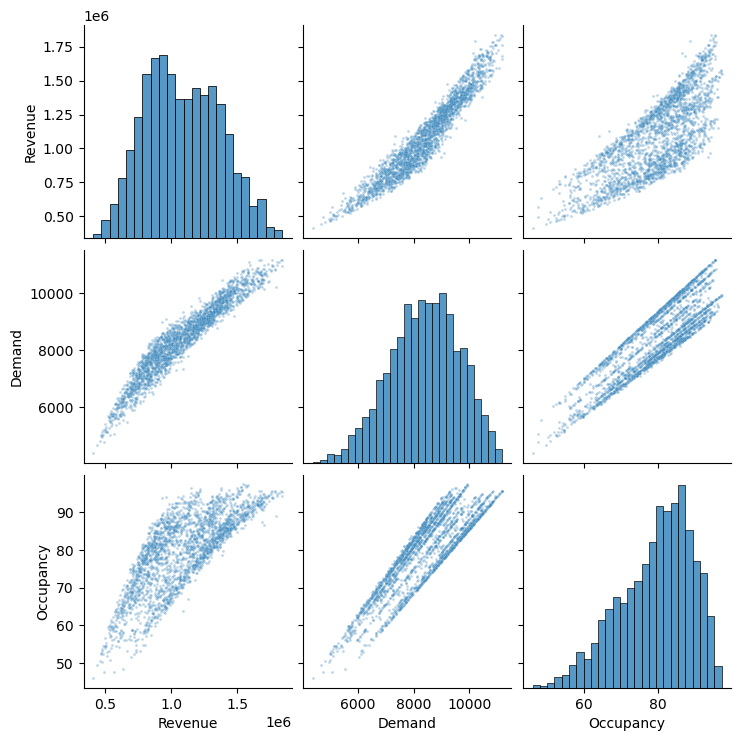

In [8]:
print(data.loc[:'2019'].corr().round(2))
sb.pairplot(data.loc[:'2019'], plot_kws=dict(s=4, alpha=0.3), height=2.5);

**Observations:**
* Revenue and Demand: correlation 0.96 (revenue is roughly rooms sold times price). Occupancy: 0.76.
* The three variables move together, so lagged Demand would add little: we use univariate models.

### 2.5 ACF / PACF
Short lags (weekly) and long lags (yearly; 364 = 52 weeks keeps the weekday aligned).

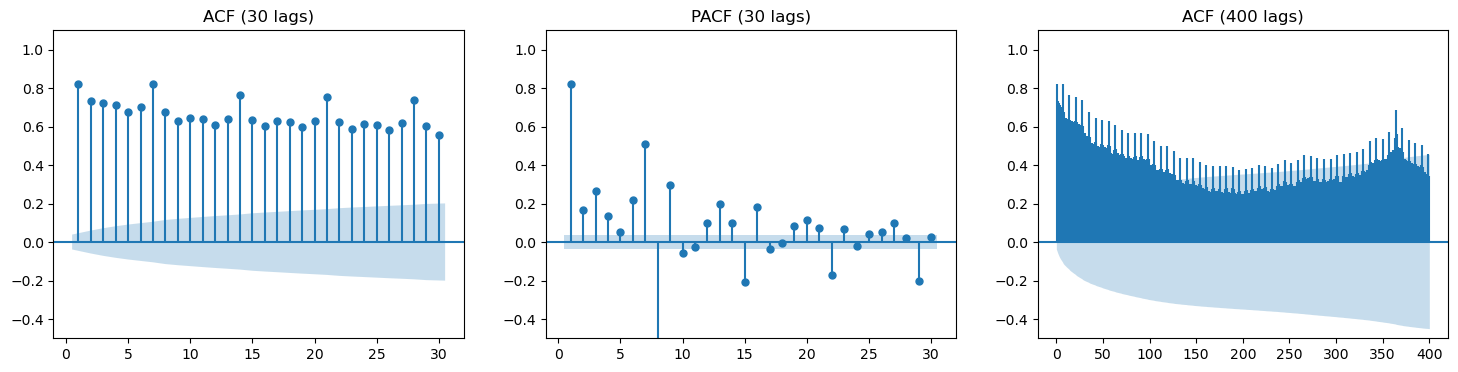

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(y_pre, lags=30, zero=False, ax=ax[0], title='ACF (30 lags)')
plot_pacf(y_pre, lags=30, zero=False, ax=ax[1], title='PACF (30 lags)')
plot_acf(y_pre, lags=400, zero=False, ax=ax[2], title='ACF (400 lags)', marker=None)

for a in ax:
    a.set_ylim(-0.5, 1.1)

**Observations:**
* The ACF decays slowly with peaks at 7, 14, 21, 28: trend and weekly seasonality, not stationary.
* The PACF has a spike at lag 1 and significant values at lags 7-9: seasonal AR/MA structure with $m=7$.
* The ACF rises again around lag 364: yearly seasonality.

### 2.6 Decomposition
MSTL (STL with periods 7 and 365) on the log series, where the seasonality becomes additive.

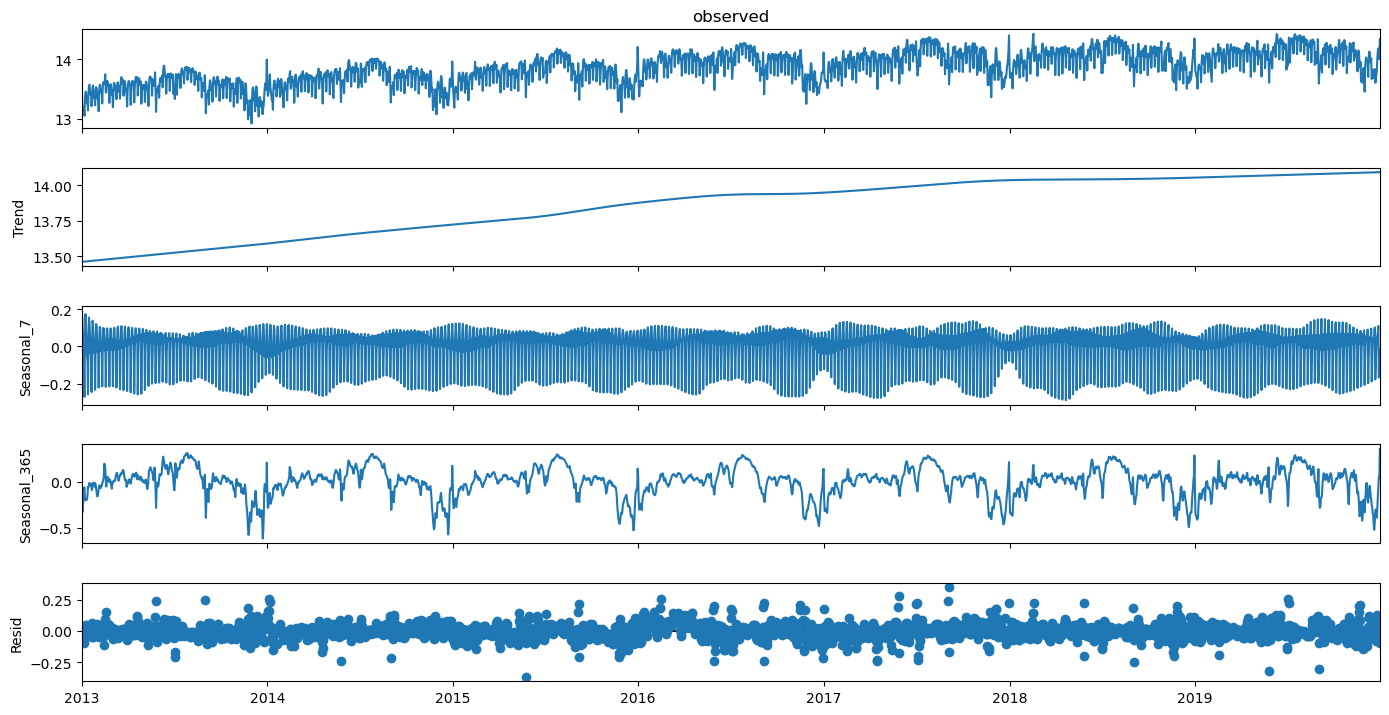

In [10]:
MSTL(np.log(y_pre), periods=(7, 365)).fit().plot().set_size_inches(14, 8)

## 3. Transformations and stationarity
### 3.1 Variance stabilisation
If the spread grows with the level, a log / Box-Cox transform makes it constant.

Box-Cox lambda (MLE) = 0.58   (0 = log)


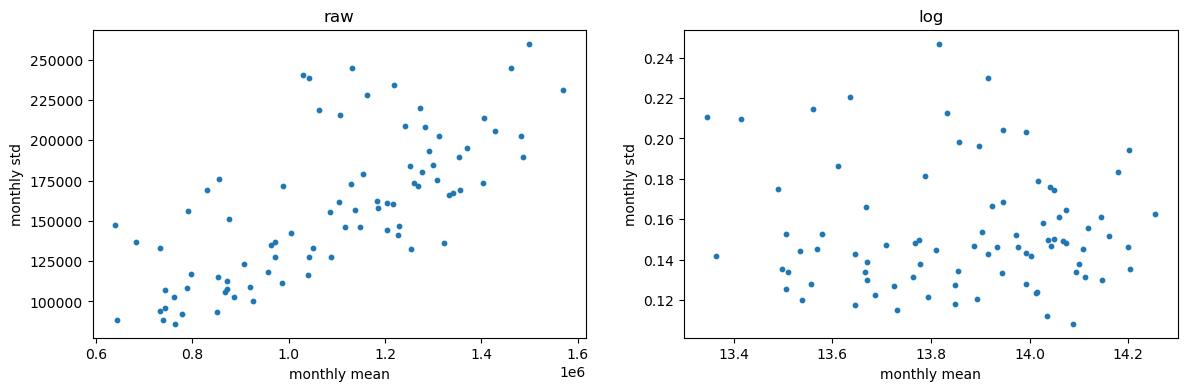

In [11]:
lam = boxcox(y_pre.values)[1]
print(f'Box-Cox lambda (MLE) = {lam:.2f}   (0 = log)')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

for a, s, name in zip(ax, [y_pre, np.log(y_pre)], ['raw', 'log']):
    r = s.resample('ME')
    a.scatter(r.mean(), r.std(), s=10)
    a.set(xlabel='monthly mean', ylabel='monthly std', title=name)

**Observations:**
* Raw series: the monthly std grows with the monthly mean.
* After the log the std no longer depends on the level.
* Box-Cox lambda = 0.58; we use the log, simpler to interpret and to back-transform.

### 3.2 Stationarity tests
| Test | H0 | H1 |
|---|---|---|
| ADF | non-stationary (unit root) | stationary |
| KPSS | stationary | non-stationary |

Stationary when the ADF p-value is small **and** the KPSS p-value is large.

In [12]:
ly = np.log(y_pre)
candidates = {
    'y': y_pre,
    'log y': ly,
    'diff7 log y': ly.diff(7),
    'diff1 diff7 log y': ly.diff(7).diff(),
}

tests = {}

for name, s in candidates.items():
    s = s.dropna()
    tests[name] = {'adf pval': adfuller(s)[1], 'kpss pval': kpss(s)[1]}

pd.DataFrame(tests).T.round(3)

,adf pval,kpss pval
y,0.076,0.01
log y,0.083,0.01
diff7 log y,0.000,0.10
diff1 diff7 log y,0.000,0.10


**Observations:**
* `y` and `log y` are not stationary (ADF p = 0.08, KPSS p = 0.01).
* `diff7 log y` is stationary (ADF p < 0.001, KPSS p = 0.10): for ARIMA on log y we expect $d=0$, $D=1$, $m=7$.
* The log does **not** make the series stationary: it only stabilises the variance. Differencing removes trend and seasonality.
* Why it matters: with a single realisation, mean and autocorrelation can only be estimated over time, which requires stationarity. ARIMA also needs it after differencing. 2020 shows what happens when it breaks.

## 4. Cross-validation setup and baselines
### 4.1 How to handle COVID
No model trained on 2013-2019 can predict the 2020 collapse, so:
* model **selection** uses the CV on **2019**;
* **2020** is only a **stress test**.

### 4.2 Rolling-origin CV
For every day $t$ the model sees only data up to $t$ and forecasts $t+1, \dots, t+7$. The same function evaluates every model.

In [13]:
H = 7


def rolling_cv(y, forecaster, start, end, h=H):
    first = y.index.get_loc(pd.Timestamp(start))
    last = y.index.get_loc(pd.Timestamp(end))
    origins = range(first, last - h + 1)

    y_hat = []
    y_true = []

    for t in origins:
        y_hat.append(forecaster(y.iloc[:t + 1], h))
        y_true.append(y.iloc[t + 1:t + 1 + h].values)

    idx = y.index[origins]
    cols = range(1, h + 1)
    return pd.DataFrame(y_true, idx, cols), pd.DataFrame(y_hat, idx, cols)

### 4.3 Baselines
* **naive:** $\hat y_{T+h} = y_T$
* **mean:** $\hat y_{T+h} = \bar y$
* **weekly seasonal naive:** $\hat y_{T+h} = y_{T+h-7}$
* **yearly seasonal naive:** $\hat y_{T+h} = y_{T+h-364}$

In [14]:
def naive(y, h):
    return np.repeat(y.iloc[-1], h)


def mean(y, h):
    return np.repeat(y.mean(), h)


def snaive_7(y, h):
    return np.tile(y.iloc[-7:].values, 2)[:h]


def snaive_364(y, h):
    return y.iloc[-364:-364 + h].values


baselines = {'naive': naive, 'mean': mean, 'snaive_7': snaive_7, 'snaive_364': snaive_364}
cv = {}
stress = {}

for name, f in baselines.items():
    cv[name] = rolling_cv(y, f, '2019-01-01', '2019-12-31')
    stress[name] = rolling_cv(y, f, '2020-01-01', '2020-10-31')

### 4.4 Error metrics
* **MAE**, also per step ahead.
* **nMAE** (course): MAE of the 7-day window divided by the std of the true values, averaged over origins.
* **MAPE**, easy to communicate.

In [15]:
def nmae(yt, yh):
    window_mae = np.abs(yt - yh).mean(axis=1)
    return (window_mae / yt.std(axis=1)).mean()


def mape(yt, yh):
    return (np.abs(yt - yh) / yt).values.mean() * 100


def scores(res):
    table = {}

    for name, (yt, yh) in res.items():
        table[name] = {
            'MAE': np.abs(yt - yh).values.mean(),
            'nMAE': nmae(yt, yh),
            'MAPE %': mape(yt, yh),
        }

    return pd.DataFrame(table).T.sort_values('MAE')


display(scores(cv).round(2))
display(scores(stress).round(2))

,MAE,nMAE,MAPE %
snaive_364,82579.94,0.51,6.45
snaive_7,142778.23,0.89,11.72
naive,189304.61,1.16,15.28
mean,295129.53,1.80,20.99


,MAE,nMAE,MAPE %
snaive_7,81762.18,1.22,13.69
naive,95479.75,1.23,13.61
mean,403859.65,11.34,96.23
snaive_364,640202.02,17.03,142.76


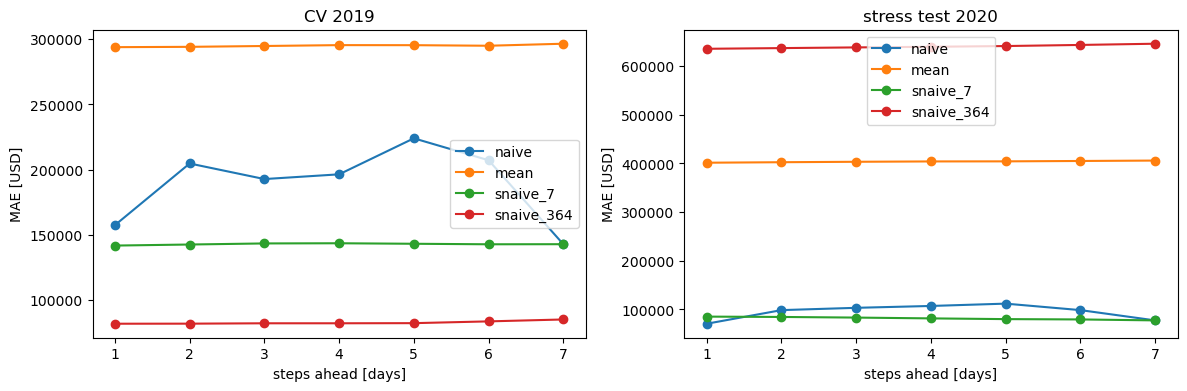

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

for a, results, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    mae_h = pd.DataFrame()

    for name, (yt, yh) in results.items():
        mae_h[name] = np.abs(yt - yh).mean()

    mae_h.plot(ax=a, marker='o')
    a.set(xlabel='steps ahead [days]', ylabel='MAE [USD]', title=title)

**Observations:**
* **2019:** the best baseline is the yearly seasonal naive (MAE 82.6k USD, MAPE 6.5%), then the weekly one (142.8k USD, 11.7%). These are the scores to beat.
* The naive error oscillates with the horizon because it ignores the weekly cycle.
* **2020:** the ranking flips. Long-memory methods fail; naive and weekly seasonal naive adapt (MAPE about 13.7%).

### 4.5 Residual check of the best baseline
Autocorrelated 1-step errors mean there is information left (Ljung-Box H0: no autocorrelation).

,lb_stat,lb_pvalue
7,302.790180,1.534032e-61
14,365.390824,2.420159e-69


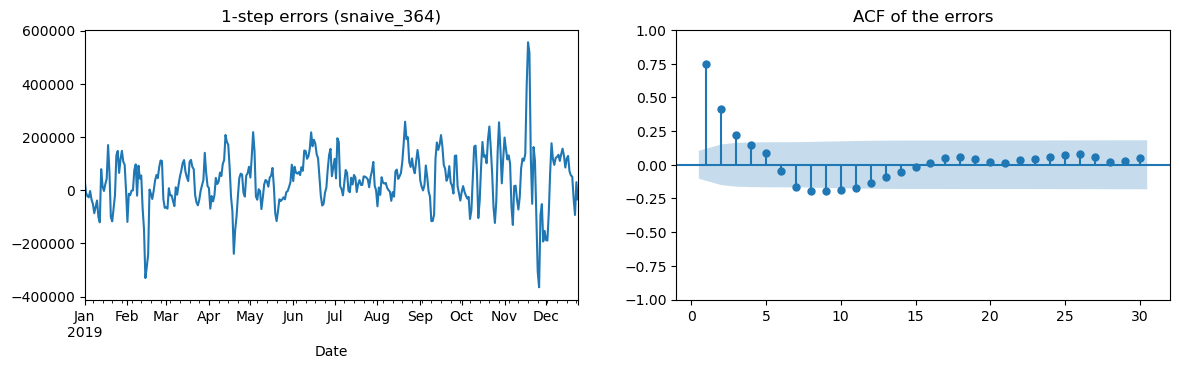

In [17]:
best = scores(cv).index[0]
y_true, y_hat = cv[best]
e1 = y_true[1] - y_hat[1]

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
e1.plot(ax=ax[0], title=f'1-step errors ({best})')
plot_acf(e1, lags=30, zero=False, ax=ax[1], title='ACF of the errors')

sm.stats.acorr_ljungbox(e1, lags=[7, 14])

**Observations:**
* The errors of the yearly seasonal naive are strongly autocorrelated (Ljung-Box p < 0.001): if this year is above last year, it stays above for several days.
* An ARIMA on these errors should improve the forecast: this is the idea of ARIMA + lag364.

## 5. Model building
### 5.1 Candidate models
All on **log y**, with `statsforecast`; orders chosen by AIC (AICc).

| Model | Weekly season | Yearly season | Idea |
|---|---|---|---|
| **ETS** | $m=7$ | none | smoothing of level and weekly pattern |
| **SARIMA** | $m=7$ | none | seasonal ARIMA, $D=1$ expected from 3.2 |
| **ARIMA + lag364** | $m=7$ | $\log y_{t-364}$ as regressor | last year's value corrected by ARIMA errors (4.5) |

`lag364` is a time embedding (embeddings lecture), used as in an ARIMAX model. It is known for the whole horizon ($h \le 7 < 364$).

In [18]:
lag364 = np.log(y).shift(364).values.reshape(-1, 1)  # NaN in 2013, so the estimation starts in 2014

models = {
    'ETS': (AutoETS(season_length=7), None),
    'SARIMA': (AutoARIMA(season_length=7), None),
    'ARIMA + lag364': (AutoARIMA(season_length=7), lag364),
}

### 5.2 Fit and CV
Parameters are **estimated once** on 2014-2018. In the CV the model is only **updated** with the new data (`forward`), not refitted: much faster, almost the same forecasts.

In [19]:
FIT = slice('2014-01-01', '2018-12-31')
s0 = y.index.get_loc(pd.Timestamp(FIT.start))


def sf_forecaster(model, X=None, y_fit=y):
    end = s0 + len(y.loc[FIT])
    y_log = np.log(y_fit.values[s0:end])

    if X is None:
        model.fit(y_log)
    else:
        model.fit(y_log, X=X[s0:end])

    def f(y_tr, h, level=None):
        n = len(y_tr)
        y_log = np.log(y_tr.values[s0:])

        if X is None:
            out = model.forward(y=y_log, h=h, level=level)
        else:
            out = model.forward(y=y_log, h=h, level=level, X=X[s0:n], X_future=X[n:n + h])

        # back to the revenue scale
        if level is None:
            return np.exp(out['mean'])

        for k in out:
            out[k] = np.exp(out[k])
        return out

    return f


forecasters = {}

for name, (m, X) in models.items():
    f = sf_forecaster(m, X)
    forecasters[name] = f
    cv[name] = rolling_cv(y, f, '2019-01-01', '2019-12-31')
    stress[name] = rolling_cv(y, f, '2020-01-01', '2020-10-31')

    if name == 'ETS':
        print(name, m.model_['method'])
    else:
        print(name, arima_string(m.model_))

ETS ETS(A,N,A)


SARIMA ARIMA(5,0,2)(2,1,0)[7]                   


ARIMA + lag364 Regression with ARIMA(1,1,2)(2,0,0)[7] errors


**Observations:**
* **ETS(A,N,A):** no trend, additive weekly season on the log (multiplicative on revenue).
* **SARIMA(5,0,2)(2,1,0)[7]:** $d=0$, $D=1$, as the tests in 3.2 suggested.
* **ARIMA + lag364**, ARIMA(1,1,2)(2,0,0)[7] errors: no seasonal difference needed, the regressor already carries the weekly and yearly pattern.

## 6. Results
### 6.1 Model selection (CV 2019) and stress test (2020)

In [20]:
res = pd.concat({'CV 2019': scores(cv), 'stress 2020': scores(stress)}, axis=1)
res.sort_values(('CV 2019', 'MAE')).round(2)

CV 2019              stress 2020               
                      MAE  nMAE MAPE %         MAE   nMAE  MAPE %
ARIMA + lag364   73727.37  0.46   5.90   116198.57   2.73   26.95
snaive_364       82579.94  0.51   6.45   640202.02  17.03  142.76
ETS             118011.62  0.70   9.50    77439.29   1.07   11.77
SARIMA          118865.68  0.72   9.60    71291.05   1.25   13.50
snaive_7        142778.23  0.89  11.72    81762.18   1.22   13.69
naive           189304.61  1.16  15.28    95479.75   1.23   13.61
mean            295129.53  1.80  20.99   403859.65  11.34   96.23

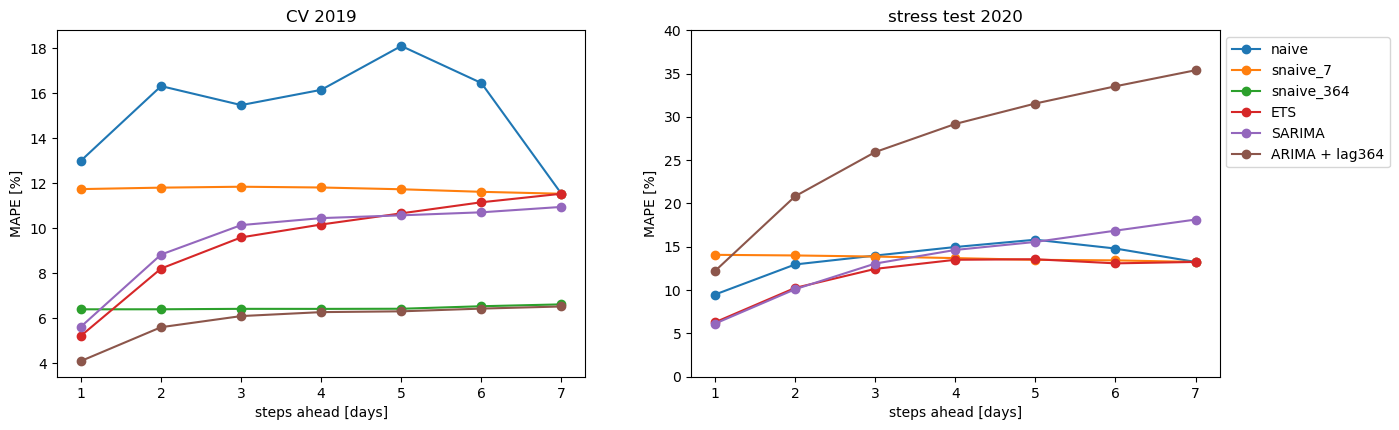

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

for a, results, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    mape_h = pd.DataFrame()

    for name, (yt, yh) in results.items():
        mape_h[name] = (np.abs(yt - yh) / yt).mean() * 100

    mape_h.drop(columns='mean').plot(ax=a, marker='o', legend=False)  # 'mean' is off the scale
    a.set(xlabel='steps ahead [days]', ylabel='MAPE [%]', title=title)

ax[1].set_ylim(0, 40)
ax[1].legend(bbox_to_anchor=(1, 1));

**Observations:**
* **Selected model: ARIMA + lag364.** MAE 73.7k USD (nMAE 0.46, MAPE 5.9%), 11% less than the best baseline.
* The gain is at short horizons (MAPE about 4% vs 6.4% at $h=1$); from $h=4$ it is close to the yearly seasonal naive.
* ETS and SARIMA degrade to about 11% at $h=7$: they have no yearly information.
* **2020:** models relying on last year fail; ETS (11.8%) and SARIMA (13.5%) are the most robust.

### 6.2 Residual diagnostics of the selected model
In-sample one-step residuals (log scale) on the estimation window.

,lb_stat,lb_pvalue
7,7.752637,0.354911
14,21.493719,0.089633


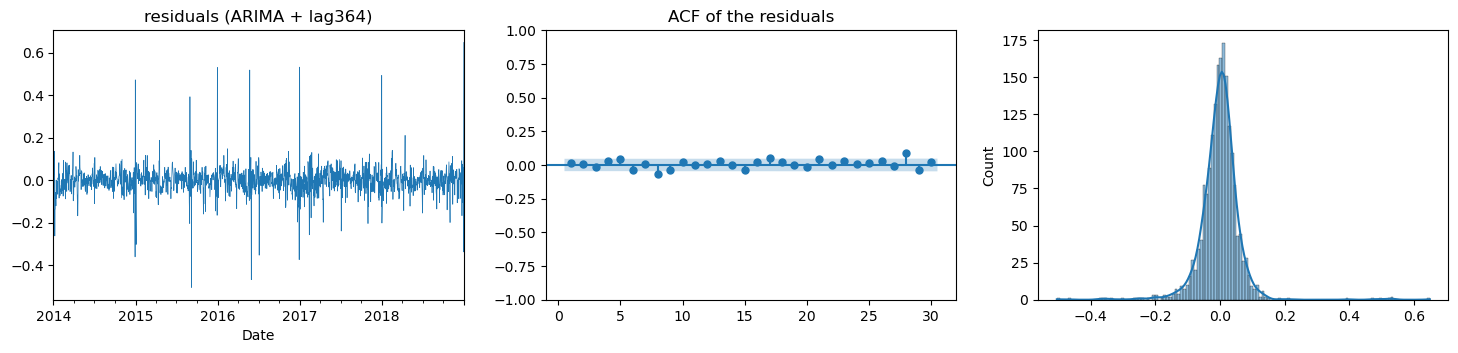

In [22]:
cv_models = {}

for name in models:
    cv_models[name] = cv[name]

best = scores(cv_models).index[0]
m, X = models[best]
fitted = m.predict_in_sample()['fitted']
resid = pd.Series(np.log(y.loc[FIT].values) - fitted, y.loc[FIT].index)

fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
resid.plot(ax=ax[0], lw=0.5, title=f'residuals ({best})')
plot_acf(resid, lags=30, zero=False, ax=ax[1], title='ACF of the residuals')
sb.histplot(resid, kde=True, ax=ax[2])

sm.stats.acorr_ljungbox(resid, lags=[7, 14])

**Observations:**
* No significant autocorrelation at lag 7 (Ljung-Box p = 0.35); lag 14 is borderline (p = 0.09).
* Centred residuals with heavy tails: spikes on holidays, especially moving ones (Thanksgiving).

### 6.3 Outlier treatment
**Why:** outliers distort the parameters and widen the intervals; with `lag364` last year's spikes are copied.

**Impute, not remove:** removing a day would shift the weekly and yearly lags.

**Hampel filter** (course) on the MSTL remainder of log y, data up to 2018: a day more than 3 std from the median of a centred 15-day window is replaced by that median.

outliers: 7 days (0.3%)


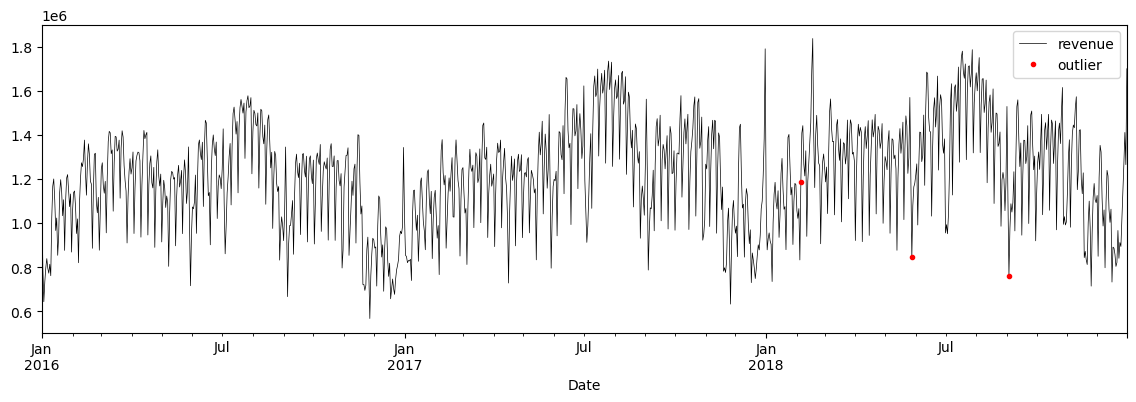

In [23]:
r = MSTL(np.log(y.loc[:'2018']), periods=(7, 365)).fit().resid
med = r.rolling(15, center=True, min_periods=1).median()
std = r.rolling(15, center=True, min_periods=1).std()

is_out = (r - med).abs() > 3 * std
out = is_out[is_out].index
print(f'outliers: {len(out)} days ({is_out.mean():.1%})')

# on the log scale: replace the remainder of the outliers with the local median
log_clean = np.log(y)
log_clean[out] = log_clean[out] - r[out] + med[out]
y_clean = np.exp(log_clean)

ax = y.loc['2016':'2018'].plot(lw=0.5, c='k', label='revenue')
y[out].loc['2016':].plot(ax=ax, ls='', marker='o', c='r', ms=3, label='outlier')
ax.legend();

In [24]:
lag364_clean = np.log(y_clean).shift(364).values.reshape(-1, 1)
f_clean = sf_forecaster(AutoARIMA(season_length=7), lag364_clean, y_clean)

name = best + ' (cleaned)'
cv[name] = rolling_cv(y, f_clean, '2019-01-01', '2019-12-31')
stress[name] = rolling_cv(y, f_clean, '2020-01-01', '2020-10-31')

cv_both = scores({best: cv[best], name: cv[name]})
stress_both = scores({best: stress[best], name: stress[name]})
pd.concat({'CV 2019': cv_both, 'stress 2020': stress_both}, axis=1).round(2)

CV 2019              stress 2020             
                               MAE  nMAE MAPE %         MAE  nMAE MAPE %
ARIMA + lag364            73727.37  0.46   5.90   116198.57  2.73  26.95
ARIMA + lag364 (cleaned)  76136.13  0.47   6.17   112878.79  2.62  26.07

**Observations:**
* 7 days flagged (0.3%), almost all Memorial Day and Labor Day weekends.
* The cleaned model is slightly worse on 2019 (MAE 76.1k vs 73.7k USD) and slightly better on 2020 (MAPE 26.1% vs 27.0%). We keep the original.
* Note: the cleaned series is also used as `lag364` input for the forecasts, which penalises the cleaned model; a fairer test would clean only the estimation data.

### 6.4 Example forecasts
7-day forecasts with 80% / 95% prediction intervals.

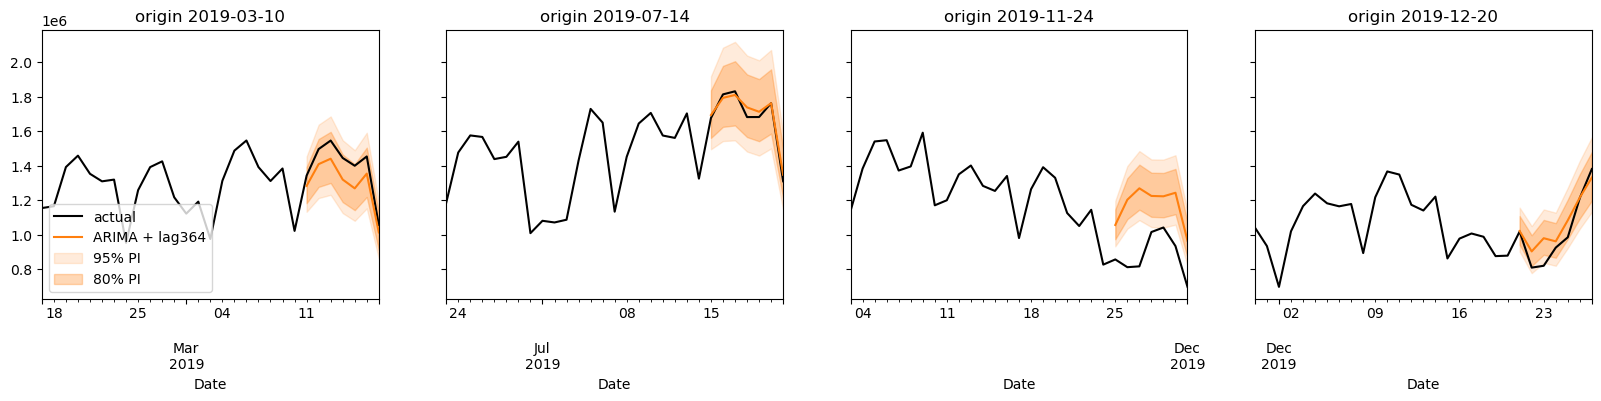

In [25]:
origins = ['2019-03-10', '2019-07-14', '2019-11-24', '2019-12-20']
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)

for a, o in zip(ax, origins):
    fc = forecasters[best](y.loc[:o], H, level=[80, 95])
    idx = pd.date_range(pd.Timestamp(o) + pd.Timedelta(days=1), periods=H)

    y.loc[pd.Timestamp(o) - pd.Timedelta(days=21):idx[-1]].plot(ax=a, c='k', label='actual')
    a.plot(idx, fc['mean'], c='C1', label=best)

    for lv, alpha in [(95, 0.15), (80, 0.3)]:
        a.fill_between(idx, fc[f'lo-{lv}'], fc[f'hi-{lv}'], color='C1', alpha=alpha, label=f'{lv}% PI')

    a.set_title(f'origin {o}')

ax[0].legend(loc='lower left');

### 6.5 Forecasts vs actual values and errors
1-day-ahead forecasts over 2019 and 2020.

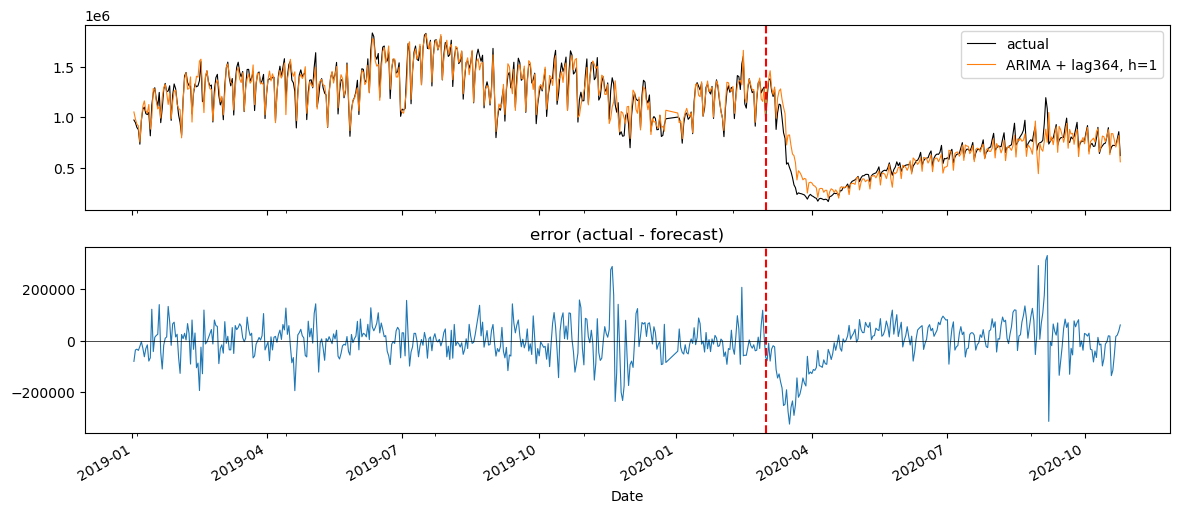

In [26]:
y_hat_cv = cv[best][1]
y_hat_stress = stress[best][1]

fc1 = pd.concat([y_hat_cv[1], y_hat_stress[1]])
fc1.index += pd.Timedelta(days=1)  # from forecast origin to forecasted day
err = y[fc1.index] - fc1

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
y[fc1.index].plot(ax=ax[0], c='k', lw=0.8, label='actual')
fc1.plot(ax=ax[0], c='C1', lw=0.8, label=f'{best}, h=1')
err.plot(ax=ax[1], lw=0.8, title='error (actual - forecast)')

for a in ax:
    a.axvline(COVID, c='r', ls='--')

ax[0].legend()
ax[1].axhline(0, c='k', lw=0.5);

**Observations:**
* 2019: errors centred on zero, spikes around holidays (late November, Christmas, New Year).
* March 2020: errors down to about -300k USD for about three weeks, then the model adapts.
* Later in 2020: larger spikes when `lag364` repeats a 2019 pattern that COVID does not.

### 6.6 Conclusions
* **Selected model:** ARIMA + lag364 (ARIMA(1,1,2)(2,0,0)[7] errors on log revenue). 2019: MAE 73.7k USD, MAPE 5.9% (about 4% at one day), better than all baselines.
* **Weak points:** moving holidays (Thanksgiving) and structural breaks (MAPE 27% in 2020).
* No model is best everywhere: lag364 in stable periods, ETS after a break.
* **Limits of our pipeline:** city chosen with the test year (2.1); outlier test not fully fair (6.3).
* **Improvements:** holiday dummies, re-estimation after a break, average of ETS and ARIMA + lag364.